<a href="https://colab.research.google.com/github/WahyuFairuzD/PCVK_Ganjil_2026/blob/main/Jobsheet10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

path = '/content/drive/MyDrive/PCVK/Images/Object Detection'

print(os.listdir(path))

['cat-template.jpg', 'cat-and-rabbit.jpg', 'sudoku.jpg', 'animal-template.jpg', 'laptop.jpg', 'chess-board.jpg', 'bahrain-template.jpg', 'cats_and_bunnies.jpg', 'animal.jpg', 'parking-lot-cars.jpg', 'bahrain.jpg', 'cat2_templatejpg.jpg', 'car-park.jpg']


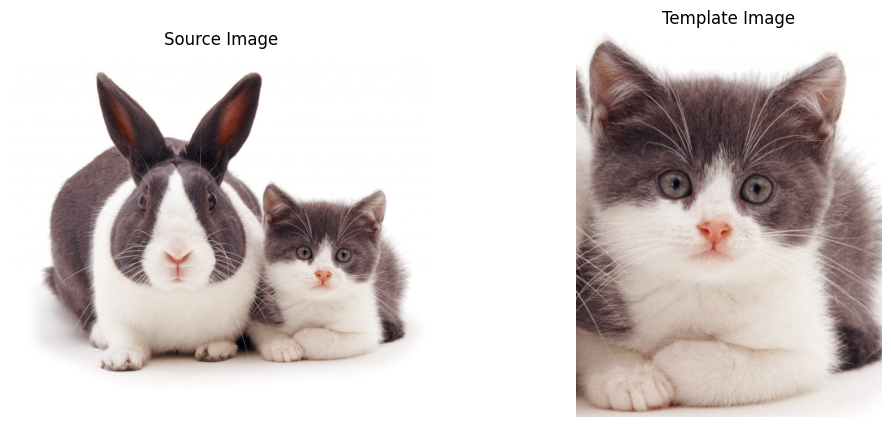

In [3]:
# Load source image and template image
img = cv.imread(path + '/cats_and_bunnies.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

template = cv.imread(path + '/cat2_templatejpg.jpg')
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

# Get template dimensions
w, h = template_gray.shape[::-1]

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Source Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
plt.title('Template Image')
plt.axis('off')

plt.show()

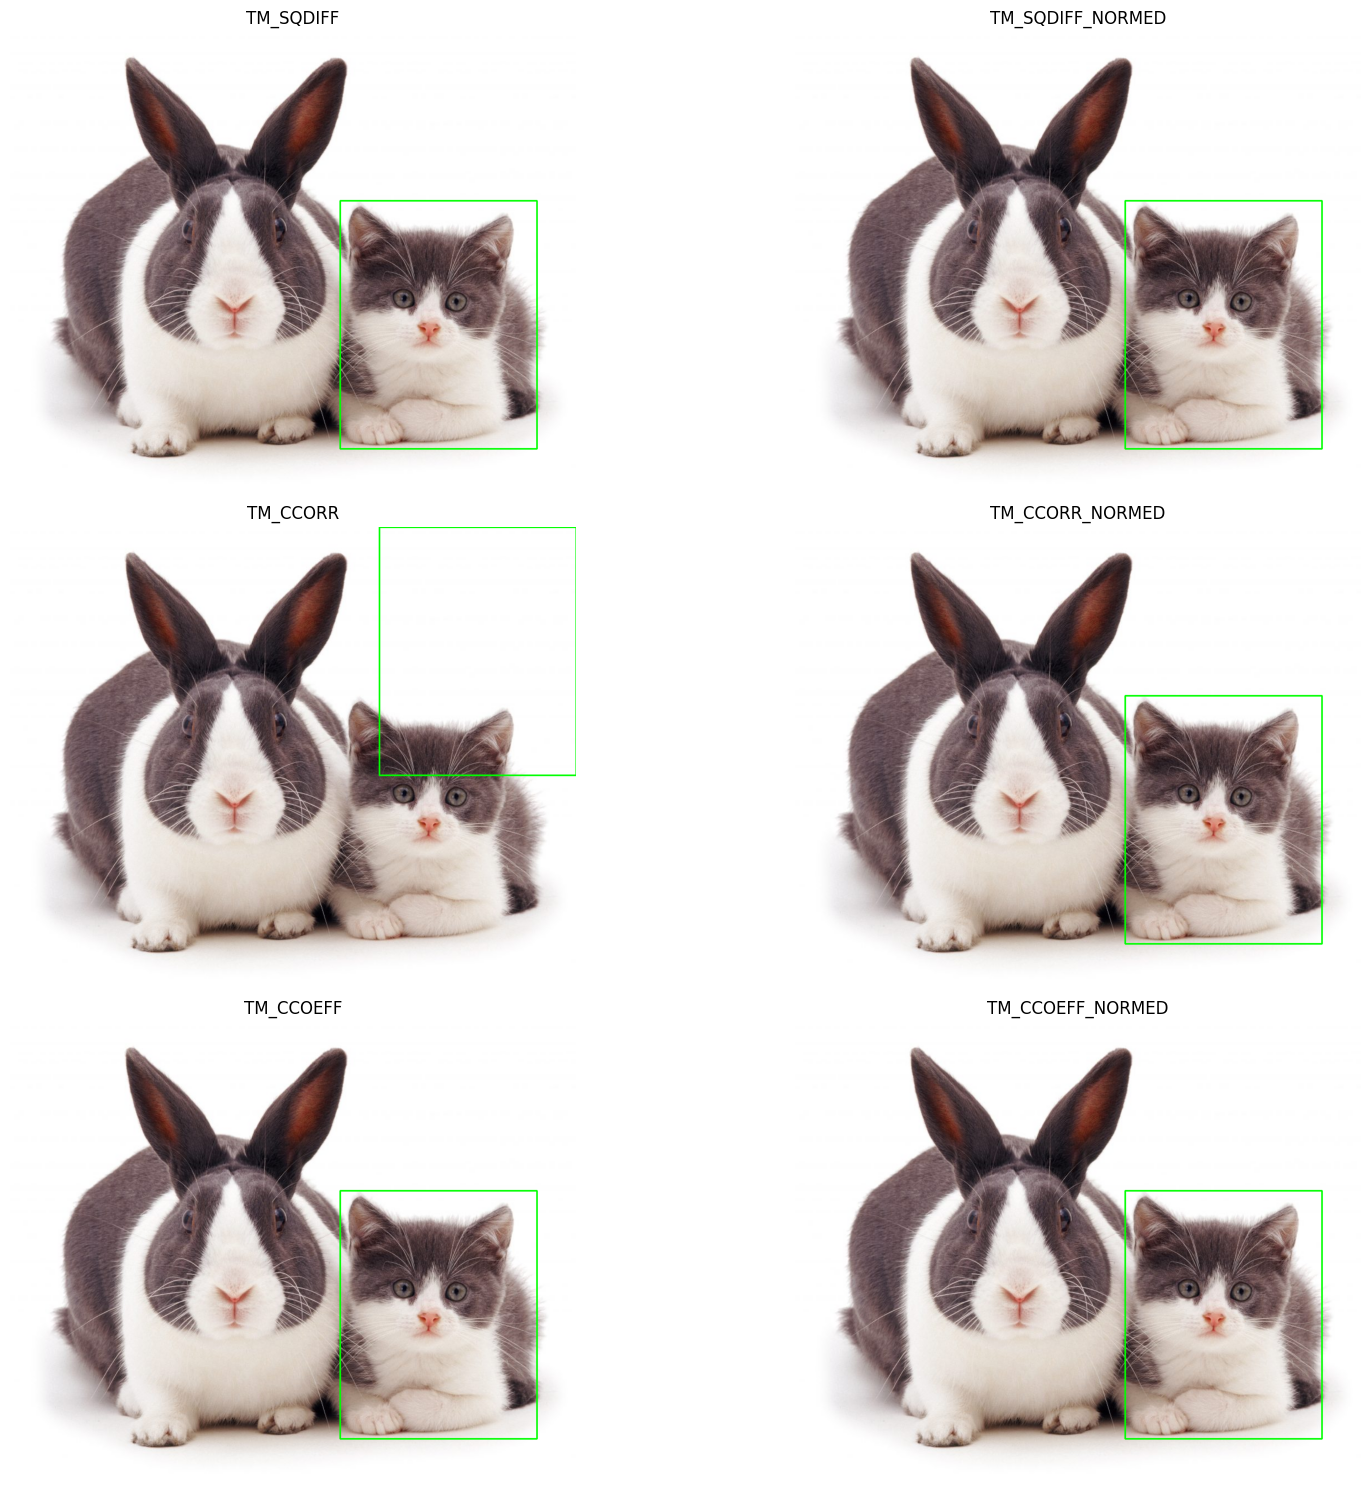

In [4]:
# Template Matching Methods
methods = [
    cv.TM_SQDIFF,
    cv.TM_SQDIFF_NORMED,
    cv.TM_CCORR,
    cv.TM_CCORR_NORMED,
    cv.TM_CCOEFF,
    cv.TM_CCOEFF_NORMED
]

titles = [
    'TM_SQDIFF',
    'TM_SQDIFF_NORMED',
    'TM_CCORR',
    'TM_CCORR_NORMED',
    'TM_CCOEFF',
    'TM_CCOEFF_NORMED'
]

plt.figure(figsize=(18, 15))

for i, method in enumerate(methods):
    result = cv.matchTemplate(
        img_gray,
        template_gray,
        method
    )

    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(result)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    img_result = img.copy()

    cv.rectangle(
        img_result,
        top_left,
        bottom_right,
        (0, 255, 0),
        2
    )

    plt.subplot(3, 2, i + 1)
    plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

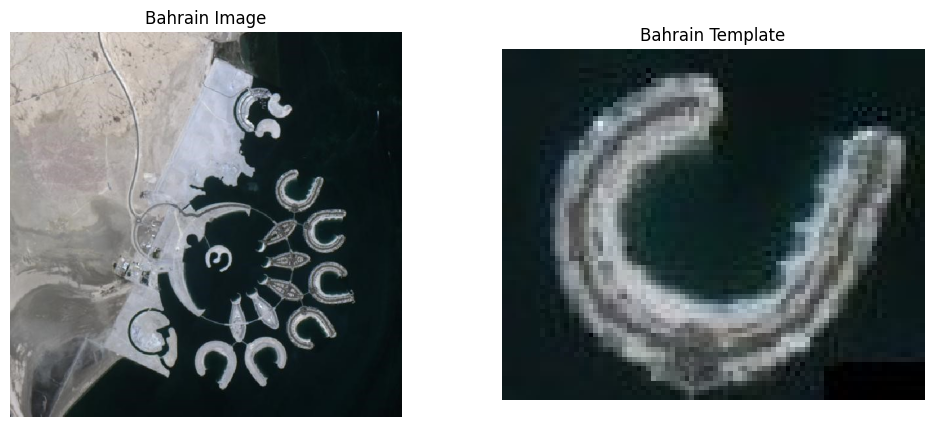

In [5]:
img = cv.imread(path + '/bahrain.jpg')
template = cv.imread(path + '/bahrain-template.jpg')

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Bahrain Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
plt.title('Bahrain Template')
plt.axis('off')

plt.show()

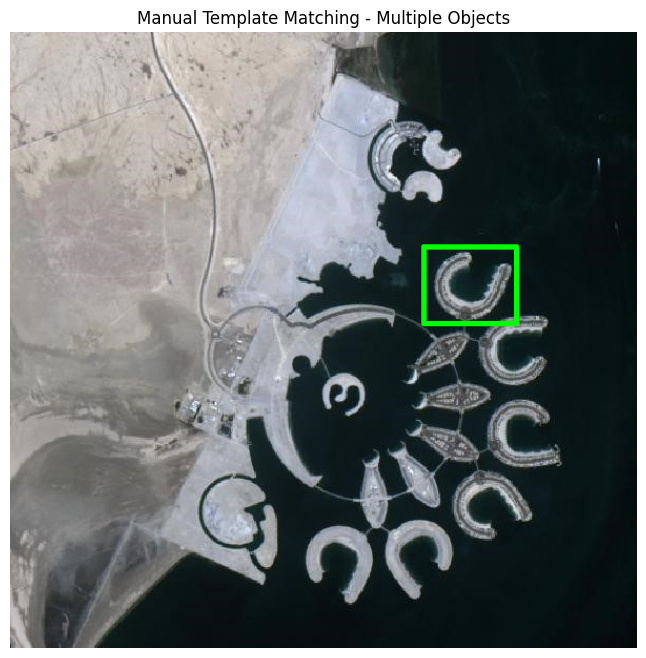

Jumlah objek terdeteksi: 8


In [6]:
# Get image dimensions
H, W = img_gray.shape
h, w = template_gray.shape

# Convert to float
img_float = img_gray.astype(np.float32)
template_float = template_gray.astype(np.float32)

# Calculate template mean
template_mean = np.mean(template_float)
template_centered = template_float - template_mean

# Calculate template norm
template_norm = np.sqrt(np.sum(template_centered ** 2))

# Matching threshold
threshold = 0.85

# Store detected locations
detections = []

# Manual template matching
for y in range(H - h + 1):
    for x in range(W - w + 1):

        region = img_float[y:y+h, x:x+w]

        region_mean = np.mean(region)
        region_centered = region - region_mean

        region_norm = np.sqrt(np.sum(region_centered ** 2))

        if region_norm == 0 or template_norm == 0:
            continue

        score = np.sum(template_centered * region_centered) / (template_norm * region_norm)

        if score >= threshold:
            detections.append((x, y, score))

# Draw detected objects
result = img.copy()

for x, y, score in detections:
    cv.rectangle(result, (x, y), (x+w, y+h), (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Manual Template Matching - Multiple Objects')
plt.axis('off')
plt.show()

print("Jumlah objek terdeteksi:", len(detections))

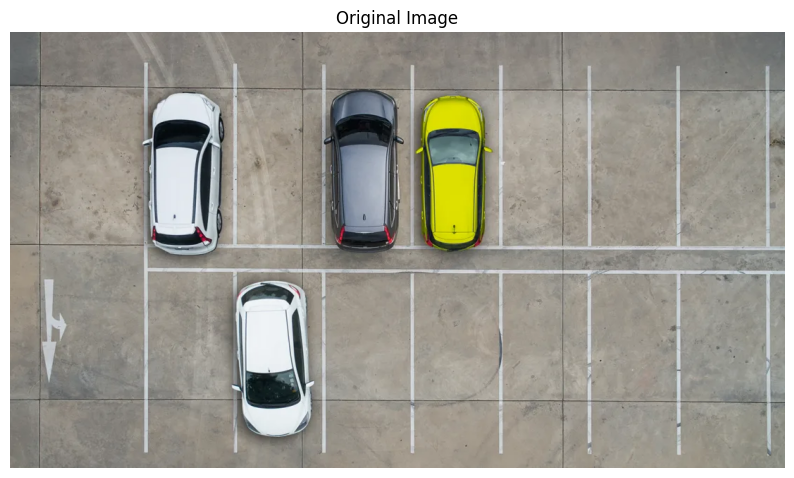

In [7]:
# Load image
img = cv.imread(path + '/car-park.jpg')

# Convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Display original image
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.show()

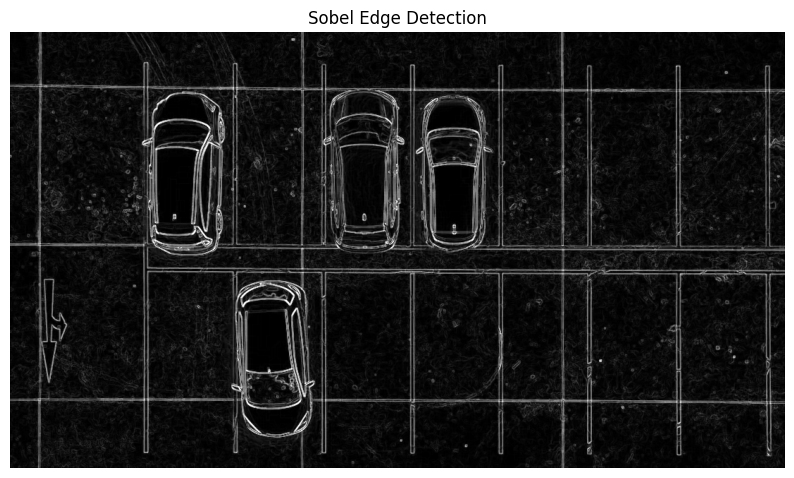

In [8]:
# Sobel Edge Detection
sobelx = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)

abs_sobelx = cv.convertScaleAbs(sobelx)
abs_sobely = cv.convertScaleAbs(sobely)

sobel = cv.addWeighted(abs_sobelx, 0.5, abs_sobely, 0.5, 0)

plt.figure(figsize=(10, 6))
plt.imshow(sobel, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')
plt.show()

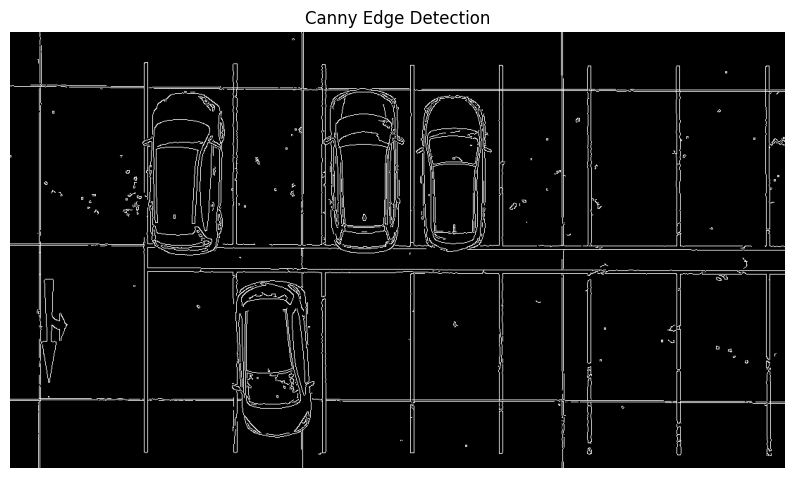

In [9]:
# Canny Edge Detection
canny = cv.Canny(gray, 100, 200)

plt.figure(figsize=(10, 6))
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.show()

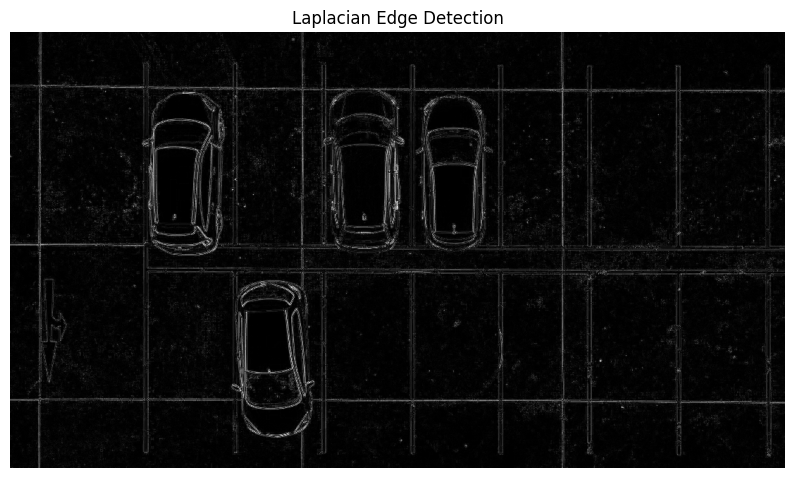

In [10]:
# Laplacian Edge Detection
laplacian = cv.Laplacian(gray, cv.CV_64F)
laplacian = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(10, 6))
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')
plt.show()

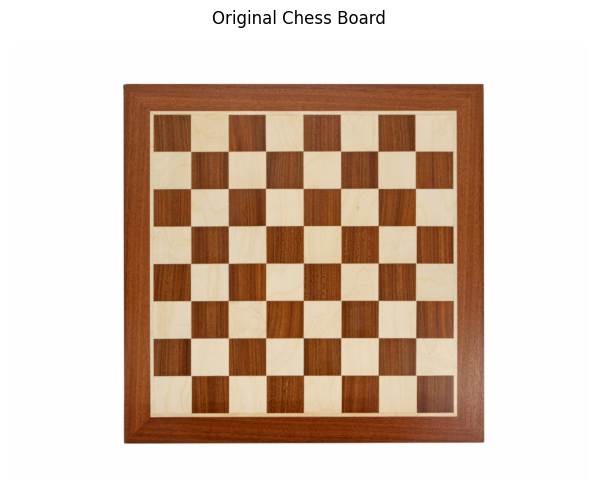

In [11]:
# Load image
img = cv.imread(path + '/chess-board.jpg')

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Chess Board')
plt.axis('off')
plt.show()

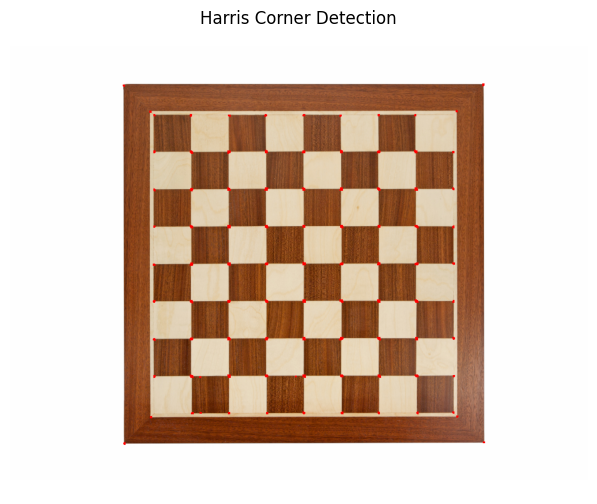

In [12]:
# Harris Corner Detection
gray_float = np.float32(gray)

dst = cv.cornerHarris(
    gray_float,
    blockSize=2,
    ksize=3,
    k=0.04
)

# Dilate corner response
dst = cv.dilate(dst, None)

# Mark detected corners
result = img.copy()
result[dst > 0.01 * dst.max()] = [0, 0, 255]

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()

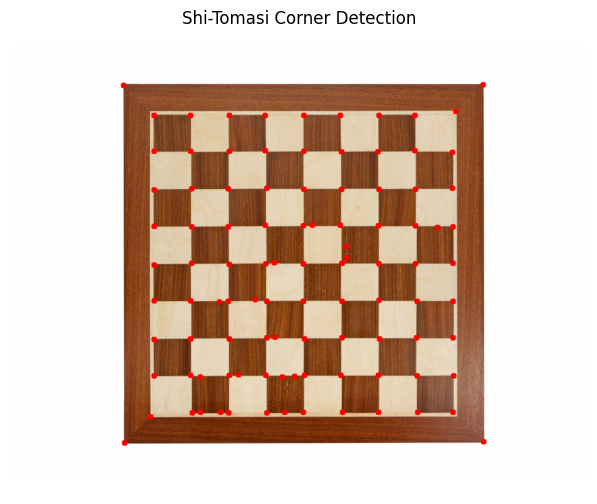

In [13]:
# Shi-Tomasi Corner Detection
corners = cv.goodFeaturesToTrack(
    gray,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=10
)

corners = np.int32(corners)

result = img.copy()

for corner in corners:
    x, y = corner.ravel()
    cv.circle(result, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')
plt.show()

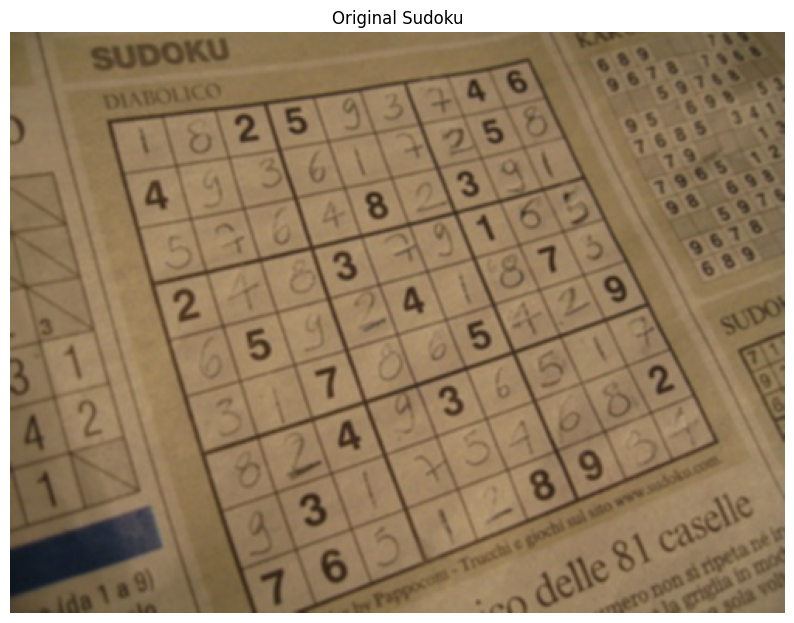

In [14]:
# Load image
img = cv.imread(path + '/sudoku.jpg')

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Sudoku')
plt.axis('off')
plt.show()

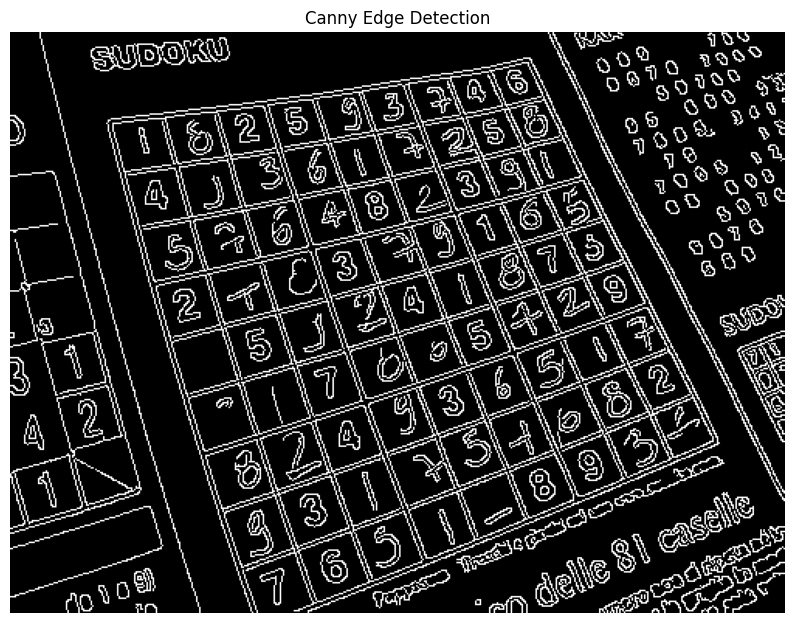

In [15]:
# Canny Edge Detection
edges = cv.Canny(gray, 50, 150)

plt.figure(figsize=(10, 8))
plt.imshow(edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.show()

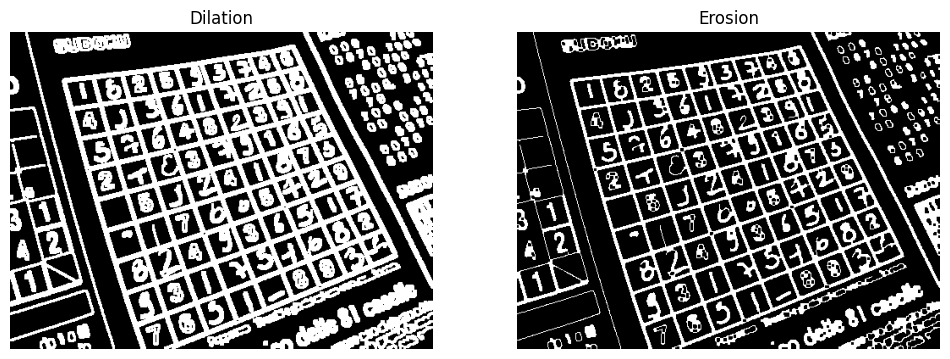

In [16]:
# Dilation
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)

# Erosion
eroded = cv.erode(dilated, kernel, iterations=1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(dilated, cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(eroded, cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.show()

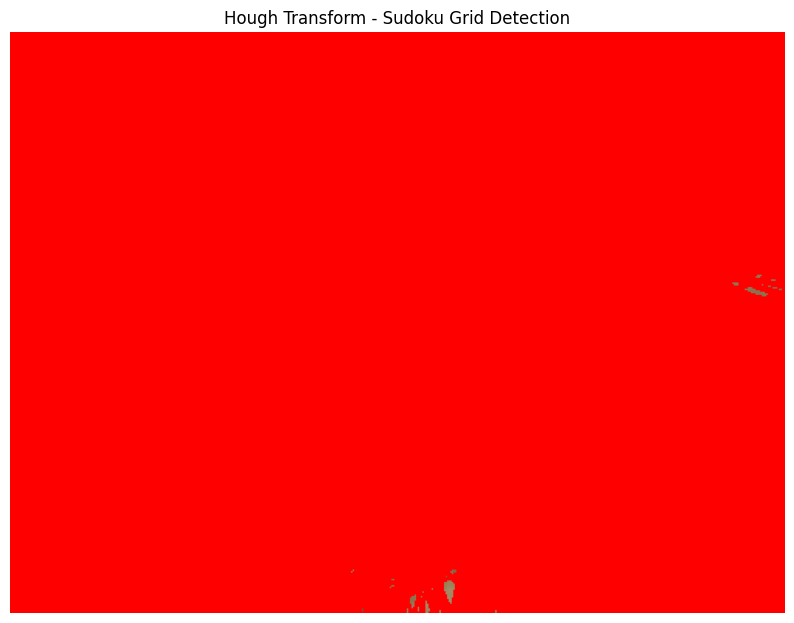

Jumlah garis terdeteksi: 2422


In [17]:
# Hough Line Transform
lines = cv.HoughLines(
    eroded,
    rho=1,
    theta=np.pi/180,
    threshold=150
)

result = img.copy()

if lines is not None:
    for line in lines:
        rho, theta = line[0]

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)

        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv.line(result, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hough Transform - Sudoku Grid Detection')
plt.axis('off')
plt.show()

print("Jumlah garis terdeteksi:", 0 if lines is None else len(lines))

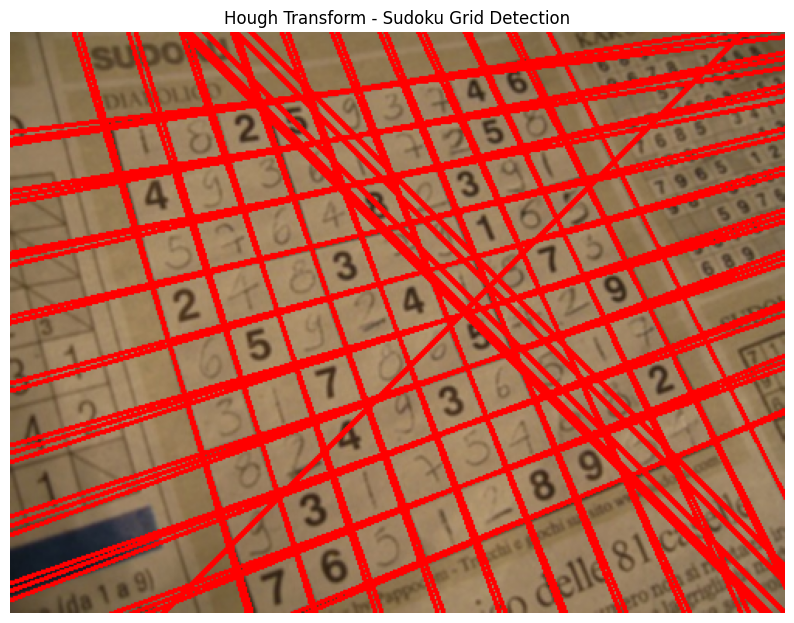

Jumlah garis terdeteksi: 54


In [18]:
# Hough Transform - Sudoku Grid Detection

lines = cv.HoughLines(
    eroded,
    rho=1,
    theta=np.pi/180,
    threshold=250
)

result = img.copy()

if lines is not None:
    for line in lines:
        rho, theta = line[0]

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))

        cv.line(result, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hough Transform - Sudoku Grid Detection')
plt.axis('off')
plt.show()

print("Jumlah garis terdeteksi:", 0 if lines is None else len(lines))

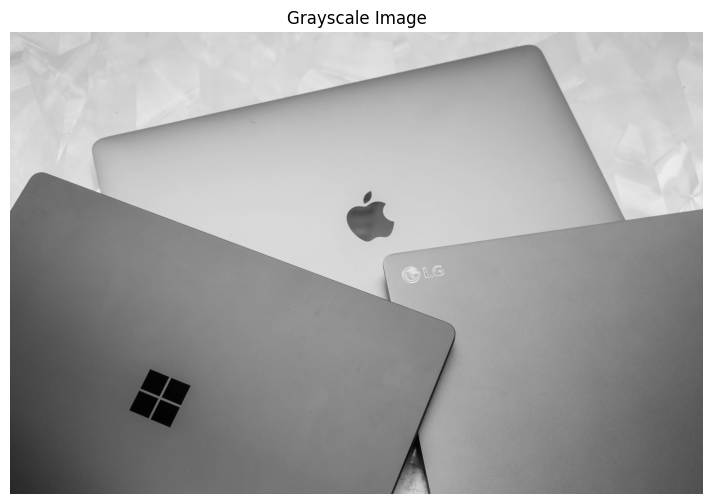

In [19]:
# Membaca gambar laptop
img = cv.imread(path + '/laptop.jpg')

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

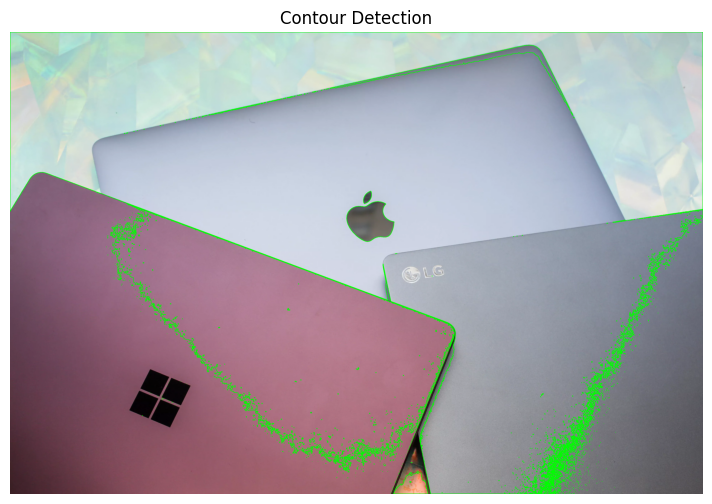

Jumlah kontur: 3413


In [20]:
# Mengubah gambar menjadi binary
ret, thresh = cv.threshold(
    gray, 127, 255, cv.THRESH_BINARY
)

# Mendeteksi kontur
contours, hierarchy = cv.findContours(
    thresh,
    cv.RETR_TREE,
    cv.CHAIN_APPROX_SIMPLE
)

# Menggambar kontur
result = img.copy()
cv.drawContours(result, contours, -1, (0, 255, 0), 2)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Contour Detection')
plt.axis('off')
plt.show()

print("Jumlah kontur:", len(contours))